In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import NaturalEarthFeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER
import dask
import glob
from dask.distributed import Client, progress

import sys
sys.path.append('/home/561/nm5072/MHW_sandbox')
import bipolarMhwToolBox as MHW

%matplotlib inline

In [2]:
from dask.distributed import Client

client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 7
Total threads: 14,Total memory: 510.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44169,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:44735,Total threads: 2
Dashboard: /proxy/38165/status,Memory: 72.86 GiB
Nanny: tcp://127.0.0.1:34581,


In [3]:
from datetime import datetime

now = datetime.now()
print(now.strftime("%H:%M:%S"))

14:28:08


In [4]:
# # --- 1. Setup Parameters ---
# base_dir = '/g/data/ia39/aus-ref-clim-data-nci/oisst/data/tmp'
# years = range(1993, 2023)
# # --- 2. Gather the file list ---
# file_list = []

# # Get all .nc files for the year (ignoring the wget script)
# for year in years:
#     files = glob.glob(f"{base_dir}/{year}/oisst-avhrr-v02r01.*.nc")
#     file_list.extend(files)
# file_list.sort()

# # CRITICAL: Chunking Strategy
# # We set time=-1 (load all time steps) but chop lat/lon into small blocks.
# # 40x40 pixels * 11,000 time steps is manageable for a single worker.
# # If you get memory errors, reduce lat/lon chunks to 20.
# chunks_config = {'time': 100, 'lat': -1, 'lon': -1}

# # --- 3. Open Dataset Efficiently ---
# # coords='minimal' and compat='override' stop xarray from reading 
# # lat/lon from every single file, which speeds up opening significantly.
# ds = xr.open_mfdataset(
#     file_list, 
#     parallel=True,       # Use multiple cores to read metadata
#     coords='minimal',    # Only load necessary coordinates
#     compat='override',   # Assume lat/lon are identical in all files (skips checking)
#     chunks=chunks_config            # Keeps data lazy (Dask) with natural 1-file chunks
# )

In [5]:
# load in prechuncked zarr
ds = xr.open_dataset('/scratch/m35/nm5072/oisst_1988-2018_rechunk_spat90.zarr',chunks={})

/jobfs/156368339.gadi-pbs/ipykernel_3633723/3271114716.py:2: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  ds = xr.open_dataset('/scratch/m35/nm5072/oisst_1988-2018_rechunk_spat90.zarr',chunks={})


In [6]:
ds.sst

<xarray.DataArray 'sst' (time: 10958, zlev: 1, lat: 720, lon: 1440)> Size: 45GB
dask.array<open_dataset-sst, shape=(10958, 1, 720, 1440), dtype=float32, chunksize=(10958, 1, 90, 90), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
  * time     (time) datetime64[ns] 88kB 1988-01-01T12:00:00 ... 2017-12-31T12...
  * zlev     (zlev) float32 4B 0.0
Attributes:
    long_name:  Daily sea surface temperature
    units:      Celsius
    valid_max:  4500
    valid_min:  -300

In [7]:
# # LAND MASK (Apply before loading to save RAM)
# mask = ds['sst'].isel(time=0).notnull()
# sst_ocean = ds['sst'].where(mask)

In [8]:
# print("Step 2: Loading entire dataset into RAM (Persisting)...")
# print("Watch the dashboard graph - this reads all files linearly.")
#  # .persist() triggers the read immediately and stores the data in the 3TB RAM
# sst_memory = sst_ocean.persist()
    
# # This blocks the script until data is loaded, showing a progress bar
# progress(sst_memory) 

In [9]:
# # --- 5. Rechunk in Memory ---
# print("\nStep 3: Rechunking in memory for MHW analysis...")
# # Now that data is in RAM, we can shuffle it instantly to the MHW shape
# # time=-1 (all history), lat/lon=90 (spatial blocks)
# sst_analysis = sst_memory.chunk({'time': -1, 'lat': 20, 'lon': 20})

In [7]:
# --- 6. Run Analysis ---
print("Calculating Climatology...")
seas = MHW.smoothedClima_mhw(ds.sst)
# Trigger computation immediately to free up graph space
seas = seas.compute() 
print("Saving Climatology...")
seas.to_netcdf('/scratch/m35/nm5072/oisst_1988-2018_global_seas.nc')
del seas # Free memory

Calculating Climatology...
Saving Climatology...


In [8]:
thresh = MHW.smoothedThresh_mhw(ds.sst)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.07/lib/python3.11/site-packages/dask/array/core.py:4998: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(


In [9]:
thresh = thresh.compute()

In [10]:
thresh.to_netcdf('/scratch/m35/nm5072/oisst_1988-2018_global_thresh.nc')

In [11]:
now = datetime.now()
print(now.strftime("%H:%M:%S"))

16:45:07


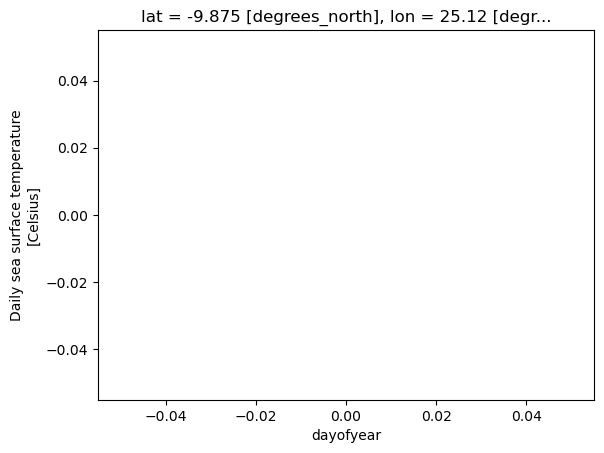

In [12]:
thresh.isel(zlev=0,lat=320,lon=100).plot()

In [13]:
print("Merging Climatology and Thresholds...")

# 1. Merge into a single Dataset for convenience
ds_climatology = xr.Dataset({
    'seas': seas,
    'thresh': thresh
})

# 2. Add Attributes (Best practice for archiving)
ds_climatology.attrs['description'] = "OISST v2.1 Climatology and 90th Percentile Threshold"
ds_climatology.attrs['baseline_period'] = "1993-2022"
ds_climatology.attrs['author'] = "Generated on NCI Gadi"

# 3. Define Compression (Saves space on /g/data)
# level 5 is the sweet spot between speed and size
encoding = {
    'seas': {'zlib': True, 'complevel': 5, 'dtype': 'float32'},
    'thresh': {'zlib': True, 'complevel': 5, 'dtype': 'float32'}
}

# 4. Save to NetCDF
output_clim_file = "/scratch/m35/nm5072/oisst_climatology_1993-2022.nc"
print(f"Saving to {output_clim_file}...")

ds_climatology.to_netcdf(output_clim_file, encoding=encoding)

Merging Climatology and Thresholds...


NameError: name 'seas' is not defined

In [18]:
thresh

<xarray.DataArray 'sst' (zlev: 1, lat: 720, lon: 1440, dayofyear: 366)> Size: 2GB
array([[[[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],

        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],

        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
...
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],

        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],

        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]]]], dtype=float32)
Coordinates:
  * lat        (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon        (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
  * zlev       (zlev) float32 4B 0.0
  * dayofyear  (dayofyear) int64 3kB 1 2 3 4 5 6 7 ... 361 362 363 364 365 366
Attributes:
    long_name:  Daily sea surface temperature
    units:      Celsius
    valid_max:  4500
    valid_min:  -300

In [ ]:
now = datetime.now()
print(now.strftime("%H:%M:%S"))

In [20]:
ds

<xarray.Dataset> Size: 45GB
Dimensions:  (lat: 720, lon: 1440, time: 10958, zlev: 1)
Coordinates:
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
  * time     (time) datetime64[ns] 88kB 1988-01-01T12:00:00 ... 2017-12-31T12...
  * zlev     (zlev) float32 4B 0.0
Data variables:
    sst      (time, zlev, lat, lon) float32 45GB dask.array<chunksize=(10958, 1, 90, 90), meta=np.ndarray>
Attributes: (12/37)
    Conventions:                CF-1.6, ACDD-1.3
    cdm_data_type:              Grid
    comment:                    Data was converted from NetCDF-3 to NetCDF-4 ...
    creator_email:              oisst-help@noaa.gov
    creator_url:                https://www.ncei.noaa.gov/
    date_created:               2020-05-08T19:05:13Z
    ...                         ...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    standard_name_vocabulary:   CF Standard Name Table (v40, 25 January 2017)
    summary:                    NOAAs 1/4-degree Daily Optimum Interpolation ...
    time_coverage_end:          1988-01-01T23:59:59Z
    time_coverage_start:        1988-01-01T00:00:00Z
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...

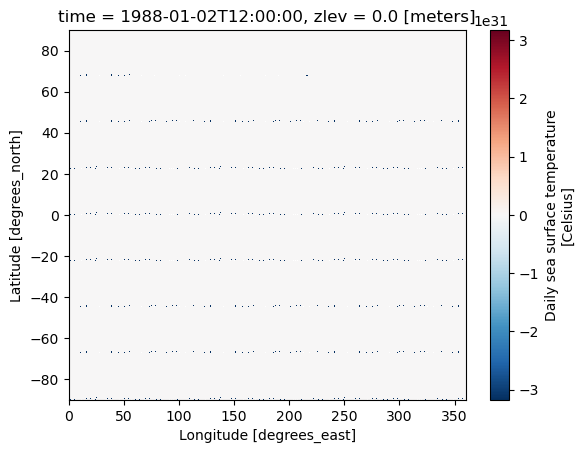

In [22]:
ds.sst.isel(time=1).plot()